# 01 — Análise exploratória (EDA)

Explora o dataset limpo (`data/processed/clean.csv`, gerado por `src/data_prep.py`) para entender o que influencia o tempo de entrega `Time_taken(min)`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# Paleta e estilo
BLUE = "#2a78d6"
RED = "#e34948"
SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_2 = "#52514e"
MUTED = "#898781"
GRID = "#e4e3df"
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", [BLUE, "#f0efec", RED])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "font.size": 10, "figure.dpi": 110,
})

TARGET = "Time_taken(min)"
DATA = Path.cwd().parent / "data" / "processed" / "clean.csv" if Path.cwd().name == "notebooks" \
    else Path("data/processed/clean.csv")

df = pd.read_csv(DATA)
print(df.shape)
df.head()

(41953, 14)


,Delivery_person_Age,Delivery_person_Ratings,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,distance_km,order_hour,day_of_week,Time_taken(min)
0,37.0,4.9,Sunny,High,2,Snack,motorcycle,0.0,No,Urban,3.025149,11.0,5,24
1,34.0,4.5,Stormy,Jam,2,Snack,scooter,1.0,No,Metropolitian,20.183530,19.0,4,33
2,23.0,4.4,Sandstorms,Low,0,Drinks,motorcycle,1.0,No,Urban,1.552758,8.0,5,26
3,38.0,4.7,Sunny,Medium,0,Buffet,motorcycle,1.0,No,Metropolitian,7.790401,18.0,1,21
4,32.0,4.6,Cloudy,High,1,Snack,scooter,1.0,No,Metropolitian,6.210138,13.0,5,30


## 1. Distribuição do tempo de entrega

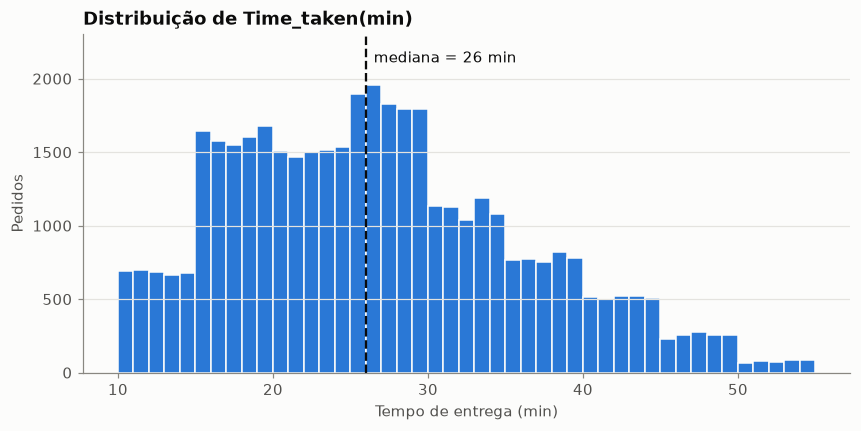

,count,mean,std,min,25%,50%,75%,max,skew
Time_taken(min),41953.0,26.3,9.4,10.0,19.0,26.0,32.0,54.0,0.48


In [2]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(df[TARGET], bins=range(10, 56), color=BLUE, edgecolor=SURFACE, linewidth=1)
ax.axvline(df[TARGET].median(), color=INK, linewidth=1.5, linestyle="--")
ax.set_ylim(0, ax.get_ylim()[1] * 1.12)
ax.text(df[TARGET].median() + 0.5, ax.get_ylim()[1] * 0.95,
        f"mediana = {df[TARGET].median():.0f} min", color=INK, va="top")
ax.set(title="Distribuição de Time_taken(min)", xlabel="Tempo de entrega (min)", ylabel="Pedidos")
ax.grid(axis="x", visible=False)
plt.show()

df[TARGET].describe().round(1).to_frame().T.assign(skew=round(df[TARGET].skew(), 2))

## 2. Distância × tempo

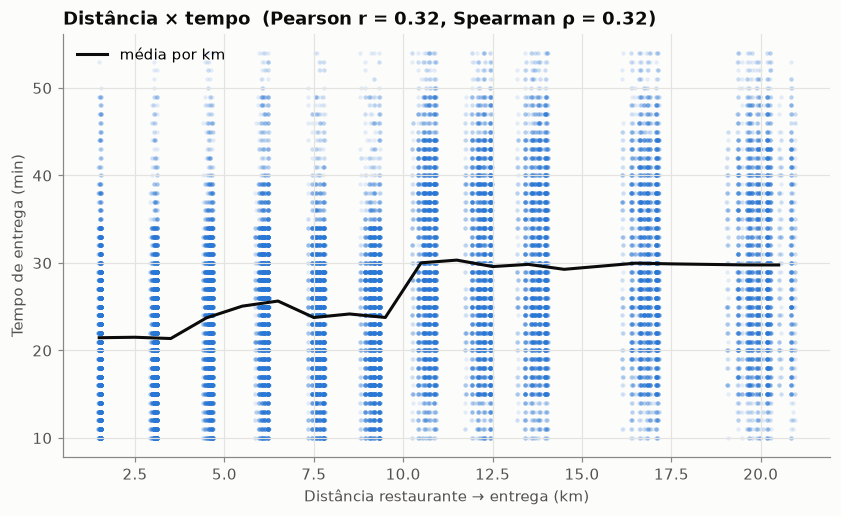

In [3]:
pearson = df["distance_km"].corr(df[TARGET])
spearman = df["distance_km"].corr(df[TARGET], method="spearman")

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(df["distance_km"], df[TARGET], s=8, alpha=0.12, color=BLUE, linewidths=0)

# Média do tempo por faixa de 1 km, para mostrar a tendência
bins = np.arange(0, df["distance_km"].max() + 1, 1)
trend = df.groupby(pd.cut(df["distance_km"], bins), observed=True)[TARGET].mean()
ax.plot([b.mid for b in trend.index], trend.values, color=INK, linewidth=2, label="média por km")

ax.set(title=f"Distância × tempo  (Pearson r = {pearson:.2f}, Spearman ρ = {spearman:.2f})",
       xlabel="Distância restaurante → entrega (km)", ylabel="Tempo de entrega (min)")
ax.legend(frameon=False, loc="upper left")
plt.show()

## 3. Tempo por variável categórica

Categorias ordenadas pela mediana do tempo (trânsito na ordem natural Low → Jam). O número em cada caixa é a quantidade de pedidos.

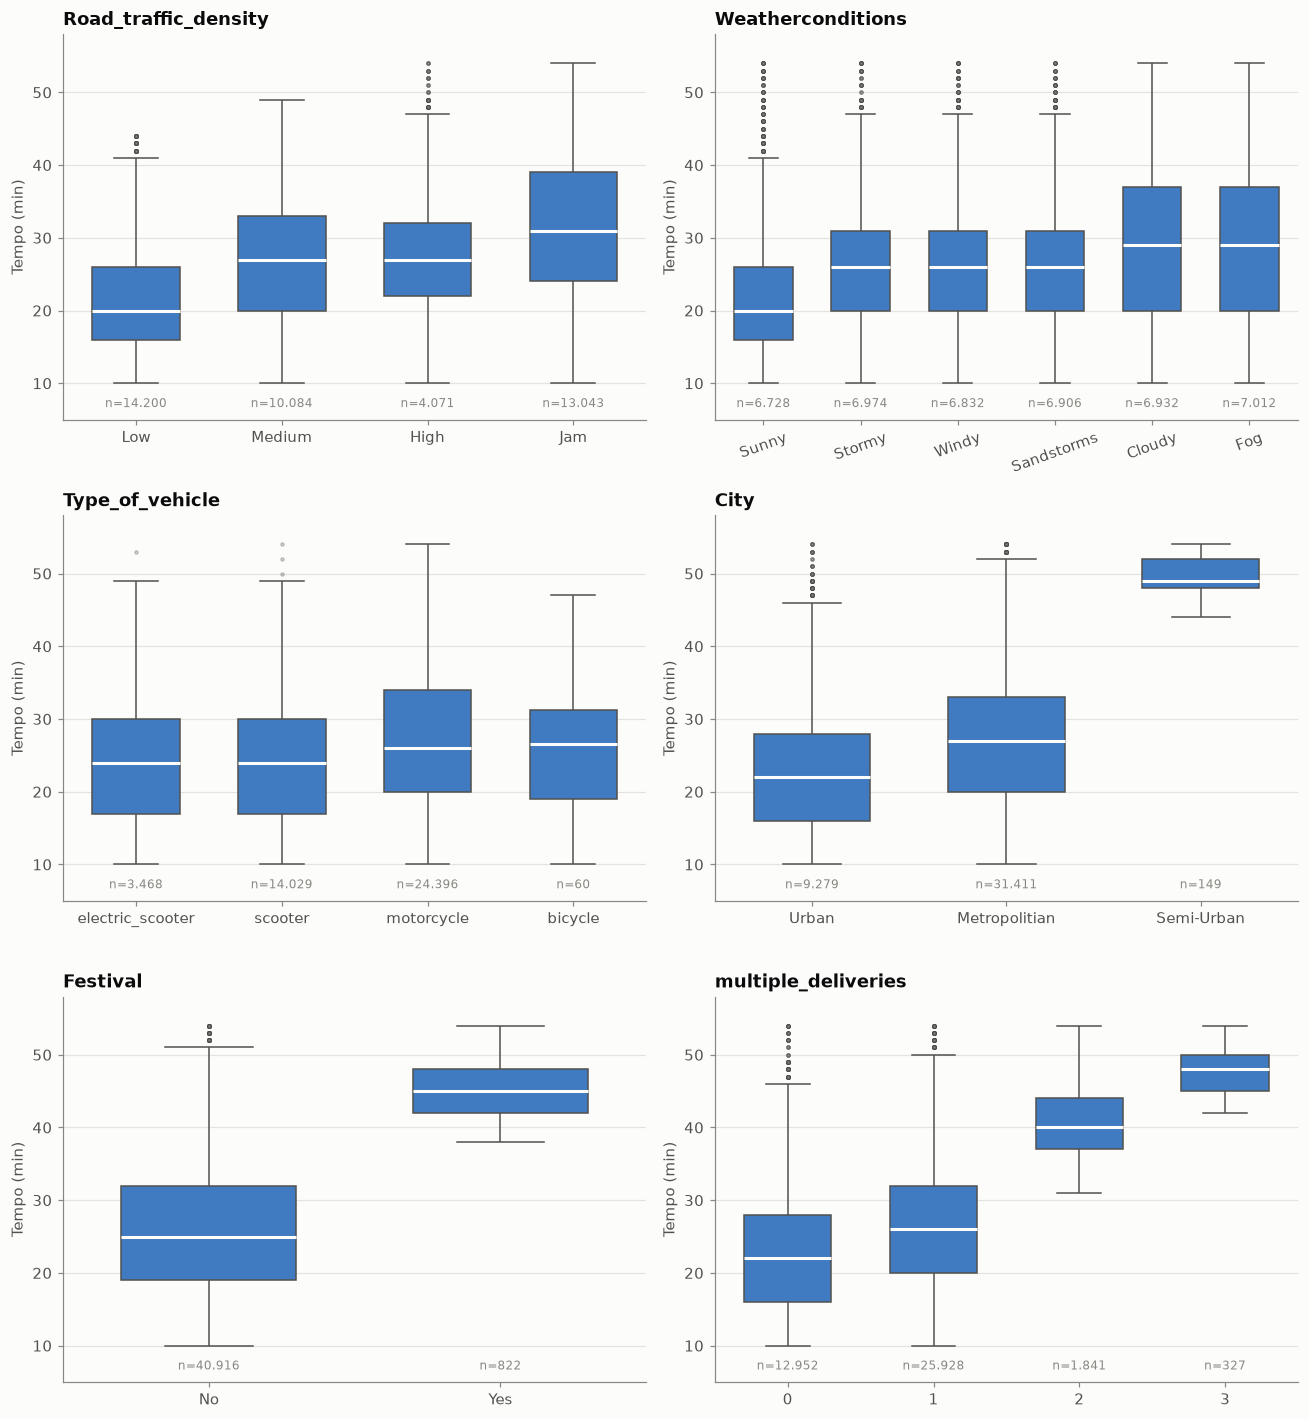

In [4]:
TRAFFIC_ORDER = ["Low", "Medium", "High", "Jam"]
cat_cols = ["Road_traffic_density", "Weatherconditions", "Type_of_vehicle",
            "City", "Festival", "multiple_deliveries"]

fig, axes = plt.subplots(3, 2, figsize=(12, 13))
for ax, col in zip(axes.flat, cat_cols):
    data = df.dropna(subset=[col])
    order = (TRAFFIC_ORDER if col == "Road_traffic_density"
             else data.groupby(col)[TARGET].median().sort_values().index)
    sns.boxplot(data=data, x=col, y=TARGET, order=order, ax=ax, color=BLUE, width=0.6,
                linewidth=1, fliersize=2, flierprops={"alpha": 0.3, "markerfacecolor": MUTED},
                medianprops={"color": SURFACE, "linewidth": 2},
                boxprops={"edgecolor": INK_2}, whiskerprops={"color": INK_2}, capprops={"color": INK_2})
    counts = data[col].value_counts()
    for i, cat in enumerate(order):
        ax.text(i, 8, f"n={counts[cat]:,}".replace(",", "."), ha="center", va="top", fontsize=8, color=MUTED)
    ax.set(title=col, xlabel="", ylabel="Tempo (min)", ylim=(5, 58))
    ax.grid(axis="x", visible=False)
    if col == "multiple_deliveries":
        ax.set_xticks(range(len(order)), [str(int(c)) for c in order])
    if col == "Weatherconditions":
        ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
plt.show()

In [5]:
# Mesma informação em tabela: média, mediana e contagem por categoria
summary = []
for col in cat_cols:
    g = df.groupby(col)[TARGET].agg(media="mean", mediana="median", n="count").round(1)
    g.index = pd.MultiIndex.from_product([[col], g.index.astype(str)])
    summary.append(g.sort_values("media"))
pd.concat(summary)

media  mediana      n
Road_traffic_density Low                21.3     20.0  14200
                     Medium             26.7     27.0  10084
                     High               27.2     27.0   4071
                     Jam                31.2     31.0  13043
Weatherconditions    Sunny              21.9     20.0   6728
                     Stormy             25.9     26.0   6974
                     Sandstorms         25.9     26.0   6906
                     Windy              26.1     26.0   6832
                     Cloudy             28.9     29.0   6932
                     Fog                29.0     29.0   7012
Type_of_vehicle      electric_scooter   24.5     24.0   3468
                     scooter            24.5     24.0  14029
                     bicycle            26.4     26.5     60
                     motorcycle         27.6     26.0  24396
City                 Urban              23.0     22.0   9279
                     Metropolitian      27.3     27.0  31411
                     Semi-Urban         49.7     49.0    149
Festival             No                 26.0     25.0  40916
                     Yes                45.5     45.0    822
multiple_deliveries  0.0                22.9     22.0  12952
                     1.0                26.9     26.0  25928
                     2.0                40.5     40.0   1841
                     3.0                47.9     48.0    327

## 4. Tempo médio por hora do pedido

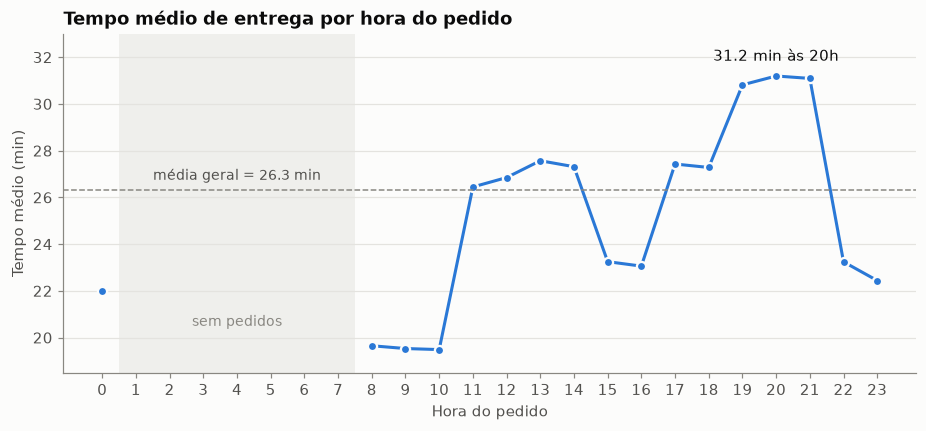

order_hour,0.0,8.0,9.0,10.0,11.0,12.0,13.0,14.0,15.0,16.0,17.0,18.0,19.0,20.0,21.0,22.0,23.0
mean,22.0,19.7,19.5,19.5,26.4,26.8,27.6,27.3,23.2,23.1,27.4,27.3,30.8,31.2,31.1,23.2,22.4
count,396.0,1676.0,1792.0,1824.0,1804.0,826.0,720.0,723.0,800.0,649.0,3945.0,4134.0,4232.0,4196.0,4316.0,4193.0,4127.0


In [6]:
by_hour = df.groupby("order_hour")[TARGET].agg(["mean", "count"])
line = by_hour["mean"].reindex(range(24))  # horas sem pedidos viram NaN e quebram a linha

fig, ax = plt.subplots(figsize=(10, 4))
ax.axvspan(0.5, 7.5, color=GRID, alpha=0.5, linewidth=0)
ax.text(4, 20.5, "sem pedidos", ha="center", color=MUTED, fontsize=9)
ax.plot(line.index, line.values, color=BLUE, linewidth=2, marker="o", markersize=6,
        markeredgecolor=SURFACE, markeredgewidth=1.5)
ax.axhline(df[TARGET].mean(), color=MUTED, linewidth=1, linestyle="--")
ax.text(4, df[TARGET].mean() + 0.3, f"média geral = {df[TARGET].mean():.1f} min",
        ha="center", va="bottom", color=INK_2, fontsize=9)
ax.set_ylim(18.5, 33)
peak = by_hour["mean"].idxmax()
ax.annotate(f"{by_hour.loc[peak, 'mean']:.1f} min às {peak:.0f}h", (peak, by_hour.loc[peak, "mean"]),
            xytext=(0, 10), textcoords="offset points", ha="center", color=INK)
ax.set(title="Tempo médio de entrega por hora do pedido", xlabel="Hora do pedido",
       ylabel="Tempo médio (min)", xticks=range(0, 24))
ax.grid(axis="x", visible=False)
plt.show()

by_hour.round(1).T

## 5. Correlação entre as variáveis numéricas

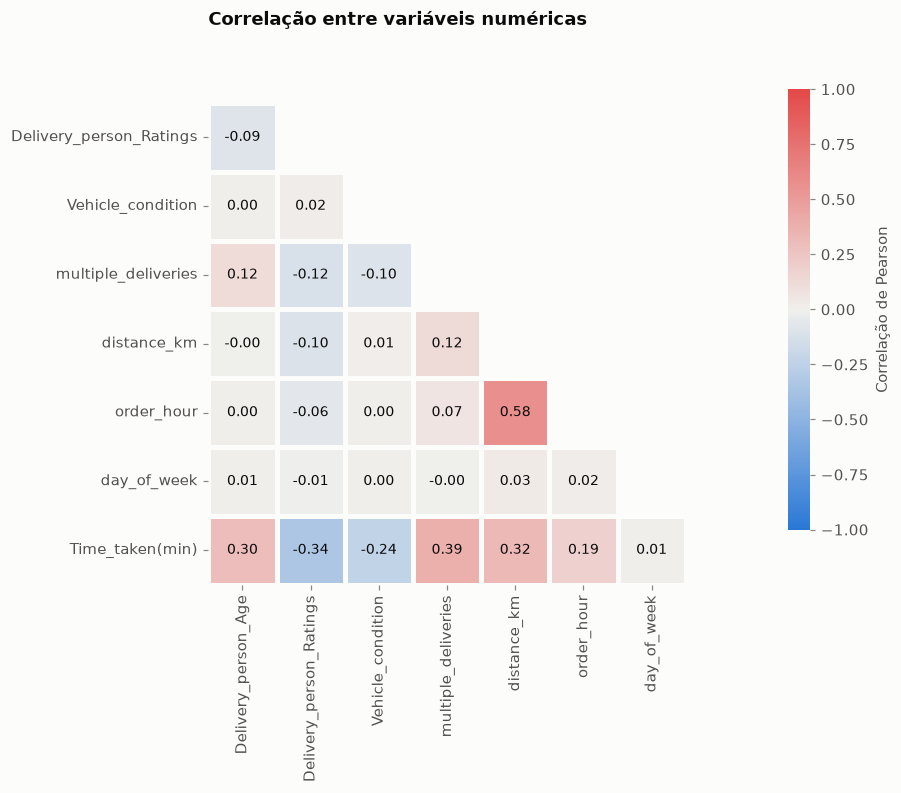

,corr com o tempo
multiple_deliveries,0.387
Delivery_person_Ratings,-0.343
distance_km,0.321
Delivery_person_Age,0.299
Vehicle_condition,-0.235
order_hour,0.185
day_of_week,0.005


In [7]:
corr = df.select_dtypes("number").corr()
mask = np.triu(np.ones_like(corr, dtype=bool))  # esconde a diagonal e o triângulo superior

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, mask=mask, cmap=DIVERGING, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"color": INK, "fontsize": 9}, linewidths=2, linecolor=SURFACE,
            cbar_kws={"shrink": 0.8, "label": "Correlação de Pearson"}, ax=ax)
ax.set_title("Correlação entre variáveis numéricas")
ax.set_xticks(ax.get_xticks()[:-1]); ax.set_yticks(ax.get_yticks()[1:])
ax.grid(False)
plt.show()

corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3).to_frame("corr com o tempo")

## Conclusões

**O alvo.** O tempo de entrega vai de 10 a 54 min, com mediana de 26 min e leve assimetria à direita (skew ≈ 0,48). Não há valores extremos absurdos, então não precisa de transformação para começar.

**Variáveis que mais parecem influenciar o tempo**, em ordem aproximada de efeito:

1. **Trânsito (`Road_traffic_density`)** — é a mais clara. A média sobe de 21 min com trânsito *Low* para 31 min com *Jam*, cerca de 10 min de diferença, com grupos grandes. *Medium* e *High* ficam parecidas (≈27 min).
2. **Entregas múltiplas (`multiple_deliveries`)** — maior correlação numérica com o alvo (r ≈ 0,39). Com 0 ou 1 entrega a média fica em 23–27 min; com 2 salta para 40 min e com 3 para 48 min.
3. **Festival** — dias de festival têm média de 45 min contra 26 min nos demais. O efeito é enorme, mas são só ~2% dos pedidos.
4. **Clima (`Weatherconditions`)** — *Sunny* é o mais rápido (22 min); *Cloudy* e *Fog* os mais lentos (29 min). Uma diferença de ~7 min.
5. **Avaliação do entregador** — correlação negativa de r ≈ −0,34: entregadores com nota mais alta entregam mais rápido.
6. **Distância (`distance_km`)** — r ≈ 0,32. A distância aparece em poucos valores discretos, e o tempo médio sobe em degrau: ≈21–25 min até ~10 km e ≈30 min acima disso. A dispersão dentro de cada distância é grande, então ela sozinha explica pouco.
7. **Idade do entregador** — r ≈ 0,30: entregadores mais velhos tendem a demorar mais.
8. **Hora do pedido (`order_hour`)** — o efeito não é linear (r ≈ 0,19 subestima). Há picos no almoço (11h–14h, ≈27 min) e principalmente no jantar (19h–21h, ≈31 min), e vales de manhã (≈20 min) e às 15h–16h e 22h–23h (≈23 min). Não há pedidos entre 1h e 7h. **Atenção:** hora e distância têm correlação de 0,58 (pedidos da noite são mais longos), então parte do efeito de uma aparece na outra.
9. **Cidade (`City`)** — *Urban* (23 min) é mais rápida que *Metropolitian* (27 min). *Semi-Urban* tem média de 50 min, mas só 149 pedidos.
10. **Estado do veículo (`Vehicle_condition`)** — r ≈ −0,24; a condição 0 (pior) tem média de 30 min contra ≈24 min nas condições 1 e 2.

**Pouca ou nenhuma influência:** `day_of_week` (r ≈ 0), e o tipo de veículo tem efeito pequeno (scooter 24,5 min, motocicleta 27,6 min; bicicleta tem só 60 pedidos).

**Próximos passos para a modelagem:**
- Muitos efeitos não são lineares (hora, entregas múltiplas, trânsito), o que favorece modelos de árvore como XGBoost.
- Codificar o trânsito como ordinal (Low < Medium < High < Jam).
- As correlações acima são entre pares: trânsito, hora e festival podem estar ligados entre si, então o efeito isolado de cada um só aparece no modelo.

## Exportar gráficos para o README

Salva em `docs/images/` os três gráficos usados no README.

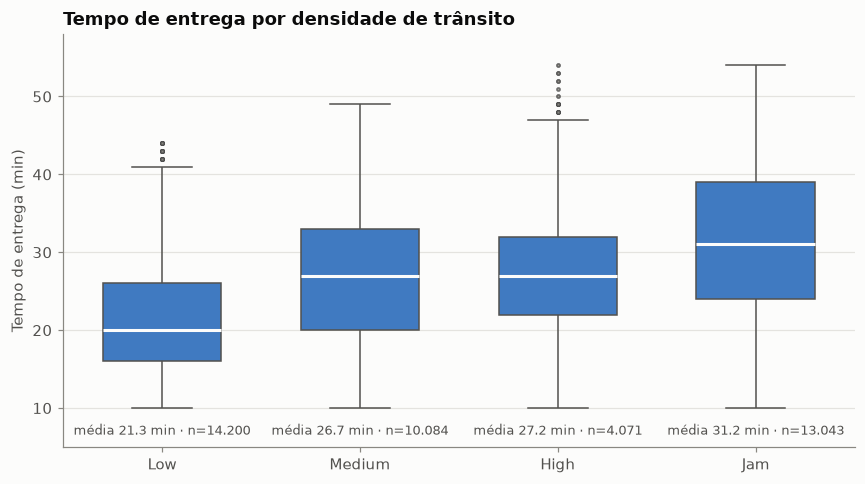

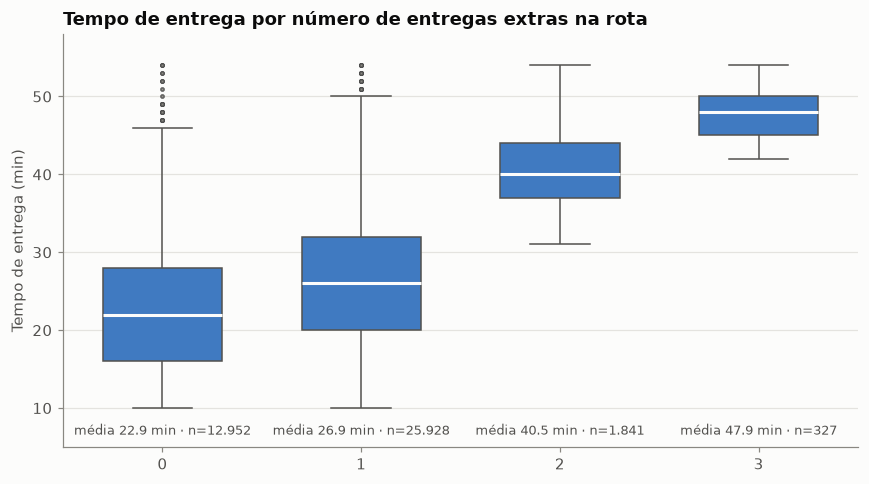

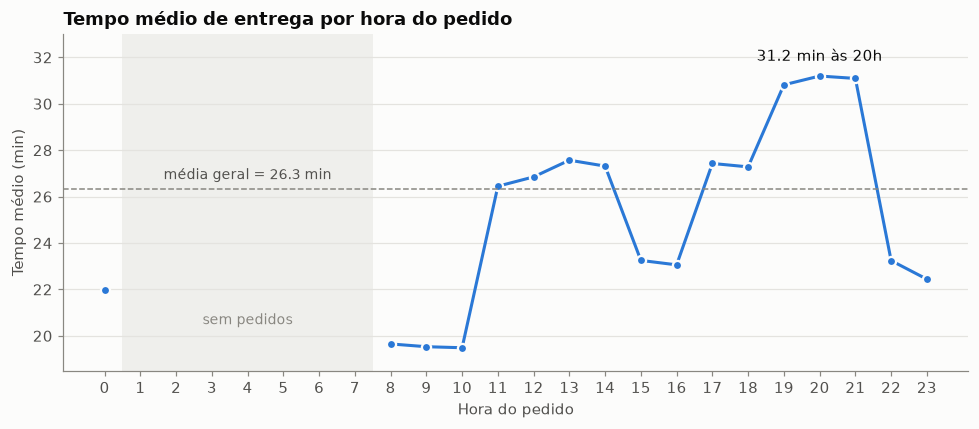

['multiple_deliveries.png', 'order_hour.png', 'traffic.png']

In [8]:
IMG_DIR = DATA.parents[2] / "docs" / "images"
IMG_DIR.mkdir(parents=True, exist_ok=True)


def export_boxplot(col, order, title, filename, xticklabels=None):
    data = df.dropna(subset=[col])
    fig, ax = plt.subplots(figsize=(8, 4.5))
    sns.boxplot(data=data, x=col, y=TARGET, order=order, ax=ax, color=BLUE, width=0.6,
                linewidth=1, fliersize=2, flierprops={"alpha": 0.3, "markerfacecolor": MUTED},
                medianprops={"color": SURFACE, "linewidth": 2},
                boxprops={"edgecolor": INK_2}, whiskerprops={"color": INK_2}, capprops={"color": INK_2})
    means = data.groupby(col)[TARGET].mean()
    counts = data[col].value_counts()
    for i, cat in enumerate(order):
        ax.text(i, 8, f"média {means[cat]:.1f} min · n={counts[cat]:,}".replace(",", "."),
                ha="center", va="top", fontsize=8.5, color=INK_2)
    ax.set(title=title, xlabel="", ylabel="Tempo de entrega (min)", ylim=(5, 58))
    if xticklabels:
        ax.set_xticks(range(len(order)), xticklabels)
    ax.grid(axis="x", visible=False)
    fig.tight_layout()
    fig.savefig(IMG_DIR / filename, dpi=150)
    plt.show()


export_boxplot("Road_traffic_density", TRAFFIC_ORDER,
               "Tempo de entrega por densidade de trânsito", "traffic.png")
export_boxplot("multiple_deliveries", [0.0, 1.0, 2.0, 3.0],
               "Tempo de entrega por número de entregas extras na rota", "multiple_deliveries.png",
               xticklabels=["0", "1", "2", "3"])

# Hora do pedido
fig, ax = plt.subplots(figsize=(9, 4))
ax.axvspan(0.5, 7.5, color=GRID, alpha=0.5, linewidth=0)
ax.text(4, 20.5, "sem pedidos", ha="center", color=MUTED, fontsize=9)
ax.plot(line.index, line.values, color=BLUE, linewidth=2, marker="o", markersize=6,
        markeredgecolor=SURFACE, markeredgewidth=1.5)
ax.axhline(df[TARGET].mean(), color=MUTED, linewidth=1, linestyle="--")
ax.text(4, df[TARGET].mean() + 0.3, f"média geral = {df[TARGET].mean():.1f} min",
        ha="center", va="bottom", color=INK_2, fontsize=9)
ax.annotate(f"{by_hour.loc[peak, 'mean']:.1f} min às {peak:.0f}h", (peak, by_hour.loc[peak, "mean"]),
            xytext=(0, 10), textcoords="offset points", ha="center", color=INK)
ax.set(title="Tempo médio de entrega por hora do pedido", xlabel="Hora do pedido",
       ylabel="Tempo médio (min)", xticks=range(0, 24), ylim=(18.5, 33))
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(IMG_DIR / "order_hour.png", dpi=150)
plt.show()

sorted(p.name for p in IMG_DIR.glob("*.png"))